In [33]:
import tensorflow as tf 


In [34]:
faqs = """Dear James,
I hope you're doing well. I’m Sophie Turner, reaching out from Swivt Technologies. I understand that you're currently looking for a skilled software developer, and I’d be glad to assist you with the right talent or solution.
we specialize in providing experienced and reliable software development professionals tailored to your specific requirements. Whether you're looking for short-term support or long-term team extension, we’re confident in our ability to meet your expectations.
Let's arrange a short call to talk about your needs and how we might help.
Looking forward to your response.
Best regards,
Anna Li
Talent Advisor
Swivt Technologies
+81-3-1234-5678
anna.li@prohire.com

Dear Michael,
I hope you're doing well. I’m Kumar Singh, reaching out from ProHire Solutions. I understand that you're currently looking for a skilled software developer, and I’d be glad to assist you with the right talent or solution
We specialize in providing experienced and reliable software development professionals tailored to your specific requirements. Whether you're looking for short-term support or long-term team extension, we’re confident in our ability to meet your expectations.
Let's arrange a short call to talk about your needs and how we might help
Looking forward to your response.

I hope you're doing well. I’m Anna Li, reaching out from TechBridge. I understand that you're currently looking for a skilled software developer, and I’d be glad to assist you with the right talent or solution.
We specialize in providing experienced and reliable software development professionals tailored to your specific requirements. Whether you're looking for short-term support or long-term team extension, we’re confident in our ability to meet your expectations.
Could we schedule a brief call to understand your needs better and explore how we can support your hiring or development goals?

I hope you're doing well. I’m Rahul Mehta, reaching out from ProHire Solutions. I understand that you're currently looking for a skilled software developer, and I’d be glad to assist you with the right talent or solution.
We specialize in providing experienced and reliable software development professionals tailored to your specific requirements. Whether you're looking for short-term support or long-term team extension, we’re confident in our ability to meet your expectations.
Could we schedule a brief call to understand your needs better and explore how we can support your hiring or development goals?

"""

In [35]:
from tensorflow.keras.preprocessing.text import Tokenizer

In [36]:
tokenizer = Tokenizer()

In [37]:

tokenizer_text=tokenizer.fit_on_texts([faqs])

In [38]:
len(tokenizer.word_index)

99

In [39]:
input_sequences = []
for sentence in faqs.split('\n'):
  tokenized_sentence = tokenizer.texts_to_sequences([sentence])[0]

  for i in range(1,len(tokenized_sentence)):
    input_sequences.append(tokenized_sentence[:i+1])

In [40]:
input_sequences

[[63, 83],
 [8, 19],
 [8, 19, 3],
 [8, 19, 3, 20],
 [8, 19, 3, 20, 21],
 [8, 19, 3, 20, 21, 22],
 [8, 19, 3, 20, 21, 22, 84],
 [8, 19, 3, 20, 21, 22, 84, 85],
 [8, 19, 3, 20, 21, 22, 84, 85, 23],
 [8, 19, 3, 20, 21, 22, 84, 85, 23, 24],
 [8, 19, 3, 20, 21, 22, 84, 85, 23, 24, 25],
 [8, 19, 3, 20, 21, 22, 84, 85, 23, 24, 25, 64],
 [8, 19, 3, 20, 21, 22, 84, 85, 23, 24, 25, 64, 65],
 [8, 19, 3, 20, 21, 22, 84, 85, 23, 24, 25, 64, 65, 8],
 [8, 19, 3, 20, 21, 22, 84, 85, 23, 24, 25, 64, 65, 8, 14],
 [8, 19, 3, 20, 21, 22, 84, 85, 23, 24, 25, 64, 65, 8, 14, 26],
 [8, 19, 3, 20, 21, 22, 84, 85, 23, 24, 25, 64, 65, 8, 14, 26, 3],
 [8, 19, 3, 20, 21, 22, 84, 85, 23, 24, 25, 64, 65, 8, 14, 26, 3, 27],
 [8, 19, 3, 20, 21, 22, 84, 85, 23, 24, 25, 64, 65, 8, 14, 26, 3, 27, 5],
 [8, 19, 3, 20, 21, 22, 84, 85, 23, 24, 25, 64, 65, 8, 14, 26, 3, 27, 5, 9],
 [8,
  19,
  3,
  20,
  21,
  22,
  84,
  85,
  23,
  24,
  25,
  64,
  65,
  8,
  14,
  26,
  3,
  27,
  5,
  9,
  10],
 [8,
  19,
  3,
  20,
  21

In [41]:
max_len = max([len(x) for x in input_sequences])

max_len

37

In [42]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
padded_input_sequences = pad_sequences(input_sequences, maxlen = max_len, padding='pre')

In [43]:
X = padded_input_sequences[:,:-1]

In [44]:
y = padded_input_sequences[:,-1]

In [45]:
from tensorflow.keras.utils import to_categorical

vocab_size = len(tokenizer.word_index) + 1  # total words
y = to_categorical(y, num_classes=vocab_size)  # shape: (samples, vocab_size)


In [46]:
from keras.models import Sequential
from keras.layers import Embedding, LSTM, Dense

model = Sequential()
model.add(Embedding(input_dim=vocab_size, output_dim=100, input_length=max_len-1))
model.add(LSTM(150))
model.add(Dense(vocab_size, activation='softmax'))  # now matches y


# Compile
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Build model explicitly to see summary
model.build(input_shape=(None, max_len-1))
model.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 36, 100)        │        10,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 150)            │       150,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        15,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,700 (686.33 KB)

 Trainable params: 175,700 (686.33 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
X.shape

(373, 36)

In [48]:
y.shape

(373, 100)

In [49]:
history = model.fit(X, y, epochs=150, verbose=1)


Epoch 1/150


2025-07-09 16:28:51.649686: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.0297 - loss: 4.6003
Epoch 2/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.0446 - loss: 4.4977
Epoch 3/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0534 - loss: 4.3167
Epoch 4/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0394 - loss: 4.1217
Epoch 5/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1021 - loss: 3.7967
Epoch 6/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1311 - loss: 3.5551
Epoch 7/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1571 - loss: 3.2630
Epoch 8/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.2563 - loss: 2.9797
Epoch 9/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.2437 - loss: 2.7640
Epoch 10/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3107 - loss: 2.6567
Epoch 11/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3347 - loss: 2.4045
Epoch 12/150
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy:

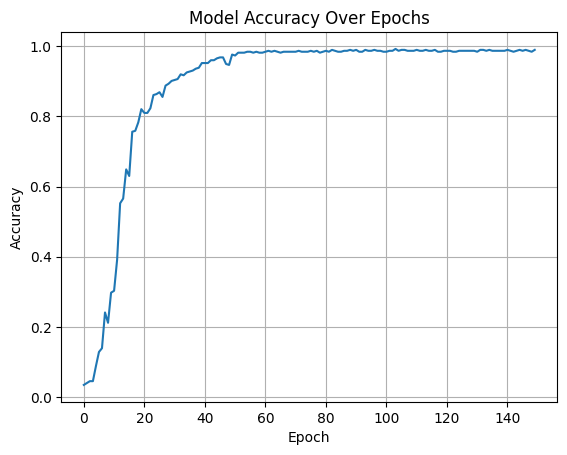

In [50]:
import matplotlib.pyplot as plt


plt.plot(history.history['accuracy'])
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

In [51]:
import time
import numpy as np
text = "my name"

for i in range(10):
  # tokenize
  token_text = tokenizer.texts_to_sequences([text])[0]
  # padding
  padded_token_text = pad_sequences([token_text], maxlen=56, padding='pre')
  # predict
  pos = np.argmax(model.predict(padded_token_text))

  for word,index in tokenizer.word_index.items():
    if index == pos:
      text = text + " " + word
      print(text)
      time.sleep(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
my name james
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
my name james james
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
my name james james prohire
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
my name james james prohire com
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
my name james james prohire com com
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
my name james james prohire com com com
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
my name james james prohire com com com com
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
my name james james prohire com com com com com
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
my name james james prohire com com com com com call
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
my name james james prohire com com com com com call to
